## 7.1. Import Utilitas

In [ ]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

## 7.2. Interpolasi Newton Maju

Metode interpolasi Newton Maju digunakan untuk memperkirakan nilai fungsi di suatu titik berdasarkan data yang memiliki jarak interval sama (uniform spacing). Metode ini memanfaatkan tabel selisih maju (forward difference) untuk membangun polinom interpolasi secara bertahap.

Polinom interpolasi Newton Maju dinyatakan sebagai:

$$
p(x) = y_0 + t\Delta y_0 +
\frac{t(t-1)}{2!}\Delta^2 y_0 +
\frac{t(t-1)(t-2)}{3!}\Delta^3 y_0 + \cdots
$$

dengan parameter:

$$
t = \frac{x - x_0}{h}
$$

Keterangan:

- $y_0$ : nilai fungsi pada titik awal $x_0$
- $h$ : jarak antar titik data ($h = x_{i+1} - x_i$)
- $\Delta y_0$ : selisih maju orde pertama
- $\Delta^2 y_0$ : selisih maju orde kedua
- $\Delta^3 y_0$ : selisih maju orde ketiga
- $t$ : variabel normalisasi posisi titik yang ingin dihitung

Metode ini sangat efektif digunakan ketika titik yang ingin diinterpolasi berada dekat dengan awal data ($x_0$).


In [ ]:
#PROGRAM

# Tabel Selisih Maju
def selisih_maju(y):

    # jumlah titik data
    n = len(y)

    # level pertama berisi data asli (orde 0)
    tabel = [y.copy()]

    # membangun selisih hingga orde ke-(n-1)
    for i in range(1, n):

        level = []

        # jumlah elemen berkurang setiap orde
        for j in range(n - i):

            # rumus selisih maju:
            # Δy_i = y_{i+1} − y_i
            selisih = tabel[i-1][j+1] - tabel[i-1][j]
            level.append(selisih)

        # simpan selisih orde berikutnya
        tabel.append(level)

    return tabel

# Fungsi Faktorial
def factorial(n):
  if n == 0:
    return 1
  else:
    return n * factorial(n-1)
  
# Fungsi Newton Maju
def newton_maju(x, y, x_target):

    # jumlah data
    n = len(y)

    # jarak antar titik (diasumsikan seragam)
    h = x[1] - x[0]

    # parameter posisi relatif terhadap titik awal
    t = (x_target - x[0]) / h

    # membangun tabel selisih maju
    tabel = selisih_maju(y)

    # pembilang polinom (t)(t-1)(t-2)...
    pemb = 1

    # nilai awal polinom = y0
    f0 = tabel[0][0]
    hasil = f0

    # menambahkan suku polinom satu per satu
    for i in range(1, n):

        # membangun perkalian bertahap:
        # t, t(t-1), t(t-1)(t-2), ...
        pemb *= (t - (i-1))

        # menambahkan suku interpolasi orde-i
        hasil += pemb * tabel[i][0] / factorial(i)

    return hasil


## 7.3. Interpolasi Newton Mundur

Metode interpolasi Newton Mundur digunakan untuk memperkirakan nilai fungsi pada suatu titik berdasarkan data dengan interval yang sama (uniform spacing). Berbeda dengan Newton Maju yang menggunakan titik awal data, metode Newton Mundur menggunakan titik akhir data sebagai acuan perhitungan.

Metode ini memanfaatkan tabel selisih mundur (backward difference) untuk membangun polinom interpolasi secara bertahap.

Polinom interpolasi Newton Mundur dinyatakan sebagai:

$$
p(x) = y_n + t\nabla y_n +
\frac{t(t+1)}{2!}\nabla^2 y_n +
\frac{t(t+1)(t+2)}{3!}\nabla^3 y_n + \cdots
$$

dengan parameter:

$$
t = \frac{x - x_n}{h}
$$

Keterangan:

- $y_n$ : nilai fungsi pada titik terakhir $x_n$
- $h$ : jarak antar titik data ($h = x_{i+1} - x_i$)
- $\nabla y_n$ : selisih mundur orde pertama
- $\nabla^2 y_n$ : selisih mundur orde kedua
- $\nabla^3 y_n$ : selisih mundur orde ketiga
- $t$ : variabel normalisasi posisi titik yang ingin dihitung

Metode Newton Mundur lebih akurat digunakan ketika titik interpolasi berada dekat dengan akhir data ($x_n$).


In [ ]:
# PROGRAM

# Tabel Selisih Munsur
def selisih_mundur(y):
    n = len(y)

    tabel = [y.copy()]   # level 0 (data asli)

    for i in range(1, n):
        level = []
        for j in range(n - i):
            selisih = tabel[i-1][j+1] - tabel[i-1][j]
            level.append(selisih)

        tabel.append(level)

    return tabel

# Fungsi Faktorial
def factorial(n):
  if n == 0:
    return 1
  else:
    return n * factorial(n-1)
  
# Fungsi Newton Maju
def newton_mundur(x, y, x_target):
    n = len(y)
    h = x[1] - x[0]
    t = (x_target - x[-1]) / h
    tabel = selisih_maju(y)

    pemb = 1 #Inisiasi Pembilang
    f0 = tabel[0][-1] # Ambil paling akhir
    hasil = f0 #hasil awal

    # Pertambahan rumus
    for i in range(1, n):
       pemb *= (t + (i-1))
       hasil += pemb * tabel[i][-1] / factorial(i)
    
    return hasil


In [ ]:
# 7.7. Plot & Galat

def plot_perbandingan(fx, x_arr, y_arr):

    x_plot = np.linspace(min(x_arr), max(x_arr), 200)

    y_true = fx(x_plot)
    y_nm = [newton_maju(x_arr, y_arr, x) for x in x_plot]
    y_nb = [newton_mundur(x_arr, y_arr, x) for x in x_plot] 

    plt.figure(figsize=(8,5))

    plt.plot(x_plot, y_true, '--', label="Fungsi Asli")
    plt.plot(x_plot, y_nm, label="Newton Maju")
    plt.plot(x_plot, y_nb, label="Newton Mundur")

    plt.scatter(x_arr, y_arr, label="Data Sampel")

    plt.title("Perbandingan Metode Interpolasi")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_error(fx, x_arr, y_arr):

    x_plot = np.linspace(min(x_arr), max(x_arr), 200)

    y_true = fx(x_plot)

    y_nm = np.array([newton_maju(x_arr,y_arr,x) for x in x_plot])
    y_nb = np.array([newton_mundur(x_arr,y_arr,x) for x in x_plot])

    # galat absolut
    err_nm = np.abs(y_true - y_nm)
    err_nb = np.abs(y_true - y_nb)

    plt.figure(figsize=(8,5))

    plt.plot(x_plot, err_nm, label="Error Newton Maju")
    plt.plot(x_plot, err_nb, label="Error Newton Mundur")

    plt.title("Galat Interpolasi terhadap x")
    plt.xlabel("x")
    plt.ylabel("|f(x) - p(x)|")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)

    plt.show()

def error_vs_grid(fx):

    jumlah_titik = [4,6,8,10,12]
    max_error = []

    x_test = np.linspace(0,1,200)
    y_true = fx(x_test)

    for n in jumlah_titik:
        x_arr = np.linspace(0,1,n)
        y_arr = fx(x_arr)

        y_interp = np.array([
            newton_maju(x_arr,y_arr,x)
            for x in x_test
        ])

        error = np.max(np.abs(y_true - y_interp))
        max_error.append(error)

    plt.figure(figsize=(7,4))
    plt.plot(jumlah_titik, max_error, marker='o')
    plt.yscale("log")
    plt.title("Max Error vs Jumlah Titik")
    plt.xlabel("Jumlah titik grid")
    plt.ylabel("Max |f - p|")
    plt.grid(True)
    plt.show()


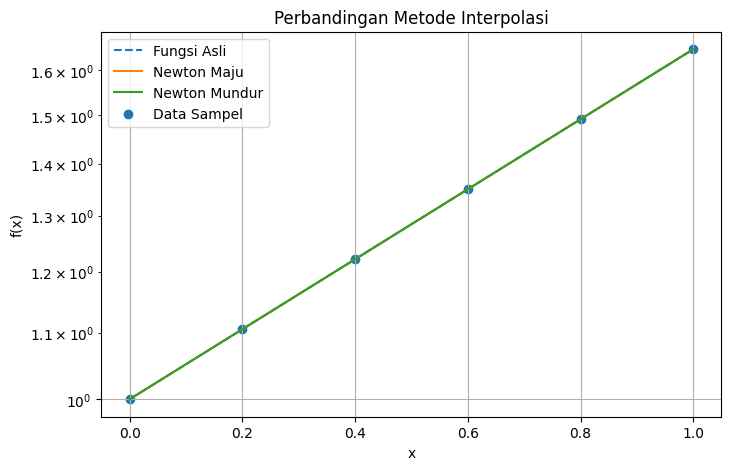

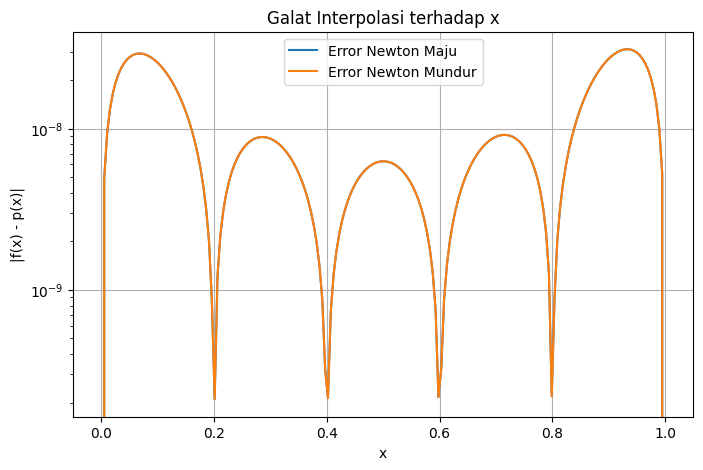

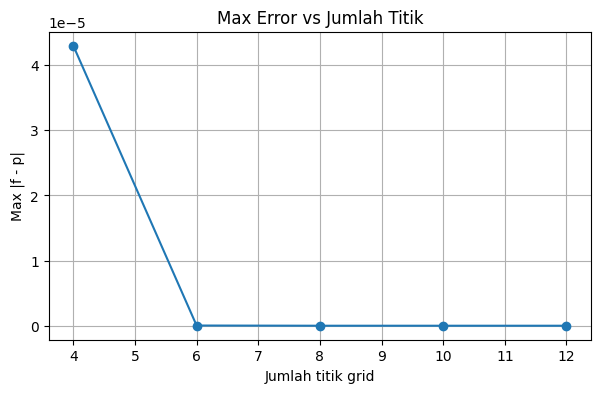

Nilai asli      : 1.191246216612358
Newton maju     : 1.1912462113120392
Newton mundur   : 1.1912462113120394

Verifikasi Newton Selisih Maju ≈ Newton Selisih Mundur: 2.220446049250313e-16


In [88]:
# 7.8 EKSPERIMEN 1

x = sp.Symbol('x')
fx = sp.E**(0.5*x)
f = sp.lambdify(x, fx, 'numpy')

# data diskret
x_arr = np.arange(0,1.2,0.2)
y_arr = f(x_arr)

x_uji = 0.35

nm = newton_maju(x_arr, y_arr, x_uji)
nb = newton_mundur(x_arr, y_arr, x_uji)
asli = f(x_uji)


plot_perbandingan(f, x_arr, y_arr)
plot_error(f, x_arr, y_arr)
error_vs_grid(f)

print("Nilai asli      :", asli)
print("Newton maju     :", nm)
print("Newton mundur   :", nb)

print("\nVerifikasi Newton Selisih Maju ≈ Newton Selisih Mundur:",
      abs(nm-nb))


In [89]:
#Data
x = sp.Symbol('x')
fx = sp.E**(0.5*x)
f = sp.lambdify(x, fx, 'numpy')

#x 
x_arr = np.arange(0,1.2,0.2)
#y
y_arr = f(x_arr)
print(len(y_arr))
print(y_arr)
print(f(0.1))

6
[1.         1.10517092 1.22140276 1.34985881 1.4918247  1.64872127]
1.0512710963760241
